## Differential equations

`ode45` solves $y' = f(t, y)$ from an initial value with an adaptive Runge-Kutta method: small steps where the solution changes fast, long ones where it doesn't. A higher-order equation becomes a first-order system by naming its derivatives: the damped pendulum's `theta'' = -(g/L) sin(theta) - c theta'` is `y = [theta; theta']`. Started nearly upside down, it swings down to rest.

In [ ]:
pendulum = @(t, y) [y(2); -9.81*sin(y(1)) - 0.3*y(2)];
[tp, yp] = ode45(pendulum, [0 20], [3; 0]);
fprintf('%d steps; the angle is %.3f rad at t = 20, the largest swing after t = 10 is %.3f rad\n', ...
    numel(tp), yp(end, 1), max(abs(yp(tp > 10, 1))))

285 steps; the angle is 0.093 rad at t = 20, the largest swing after t = 10 is 0.476 rad


Lorenz's system, with his `sigma = 10`, `rho = 28` and `beta = 8/3`, never settles and never repeats, yet stays on a butterfly-shaped set; nearby starting points separate exponentially fast. The figure shows one solution seen along the y axis.

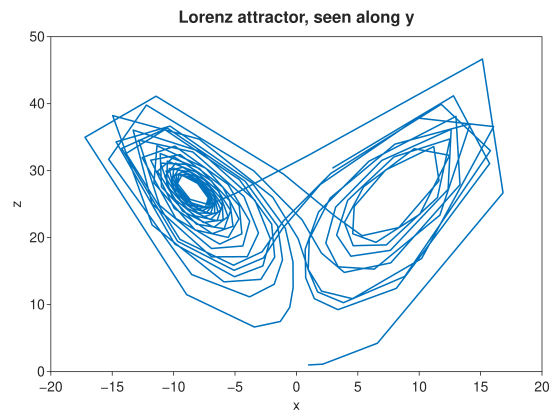

In [ ]:
figure
lorenz = @(t, u) [10*(u(2) - u(1)); u(1)*(28 - u(3)) - u(2); u(1)*u(2) - 8/3*u(3)];
[tl, ul] = ode45(lorenz, linspace(1, 25, 240), [1; 1; 1]);
plot(ul(:, 1), ul(:, 3), 'LineWidth', 0.6), xlabel('x'), ylabel('z'), title('Lorenz attractor, seen along y')

A second solution started $10^{-6}$ away: the distance between the two stays small for a while, then grows about tenfold every two or three time units. The tolerances are tightened with `odeset`, but they control the solver's local error estimates at each step, not the global error of a chaotic solution, so this is a numerical illustration.

In [ ]:
opts = odeset('RelTol', 1e-8, 'AbsTol', 1e-10);
times = 0:5:25;
[~, ua] = ode45(lorenz, times, [1; 1; 1], opts);
[~, ub] = ode45(lorenz, times, [1 + 1e-6; 1; 1], opts);
fprintf('t = %2d: distance %.1e\n', [times; sqrt(sum((ua - ub).^2, 2))'])

t =  0: distance 1.0e-06
t =  5: distance 1.2e-06
t = 10: distance 1.8e-06
t = 15: distance 2.4e-05
t = 20: distance 9.3e-04
t = 25: distance 1.4e-01


The van der Pol oscillator `x'' - mu (1 - x^2) x' + x = 0` pumps energy in at small amplitude and damps it at large amplitude, so solutions are drawn to one closed orbit, a limit cycle: one started near rest and one started far out end with the same amplitude, about 2.

In [ ]:
vdp = @(t, y) [y(2); 1.5*(1 - y(1)^2)*y(2) - y(1)];
[ti, yi] = ode45(vdp, [0 40], [0.1; 0]);
[to, yo] = ode45(vdp, [0 40], [4; 3]);
fprintf('amplitude after t = 30: %.3f from near rest, %.3f from far out\n', max(abs(yi(ti > 30, 1))), max(abs(yo(to > 30, 1))))

amplitude after t = 30: 2.027 from near rest, 2.029 from far out


*Thanks to MatRust-Studio (MIT license), whose examples suggested these topics; the code here is Sagebrush's own.*